<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/08_yearly_weights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08 - Equal-risk weights, recomputed every year

In 07 the equal-risk weights were computed on the whole 2004-2026 period, so they knew the future. Here they are recomputed on the first trading day of each year with the last 1000 days only, and kept for the year. Same seven assets.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk import *

assets = ["spx", "aapl", "msft", "jpm", "xom", "gld", "tlt"]
prices = pd.concat({a: load_close("../black-scholes-sp500/data/sp500.csv" if a == "spx" else f"data/{a}.csv") for a in assets},
                   axis=1).dropna()
simple = np.exp(np.log(prices).diff().dropna()) - 1

W = rolling_equal_risk_weights(simple, window=1000)
start = W.dropna().index[0]
yearly = W.dropna().groupby(W.dropna().index.year).first()
print("first year:", start.date())
print(yearly.round(2))

first year: 2009-01-02
       spx  aapl  msft   jpm   xom   gld   tlt
Date                                          
2009  0.05  0.05  0.06  0.05  0.05  0.15  0.59
2010  0.06  0.07  0.07  0.04  0.06  0.19  0.51
2011  0.06  0.07  0.07  0.04  0.06  0.19  0.51
2012  0.07  0.08  0.07  0.04  0.06  0.19  0.50
2013  0.10  0.11  0.10  0.04  0.14  0.20  0.33
2014  0.10  0.08  0.10  0.08  0.12  0.10  0.42
2015  0.11  0.08  0.12  0.08  0.10  0.10  0.41
2016  0.11  0.09  0.10  0.10  0.09  0.13  0.37
2017  0.11  0.09  0.09  0.11  0.09  0.15  0.35
2018  0.11  0.10  0.08  0.10  0.09  0.26  0.26
2019  0.08  0.08  0.07  0.09  0.08  0.27  0.33
2020  0.09  0.07  0.07  0.10  0.08  0.23  0.35
2021  0.07  0.07  0.07  0.06  0.06  0.18  0.49
2022  0.07  0.07  0.07  0.06  0.06  0.20  0.47
2023  0.08  0.07  0.07  0.07  0.07  0.22  0.41
2024  0.08  0.07  0.07  0.07  0.07  0.22  0.41
2025  0.10  0.09  0.08  0.12  0.11  0.23  0.26
2026  0.09  0.07  0.08  0.09  0.09  0.27  0.31


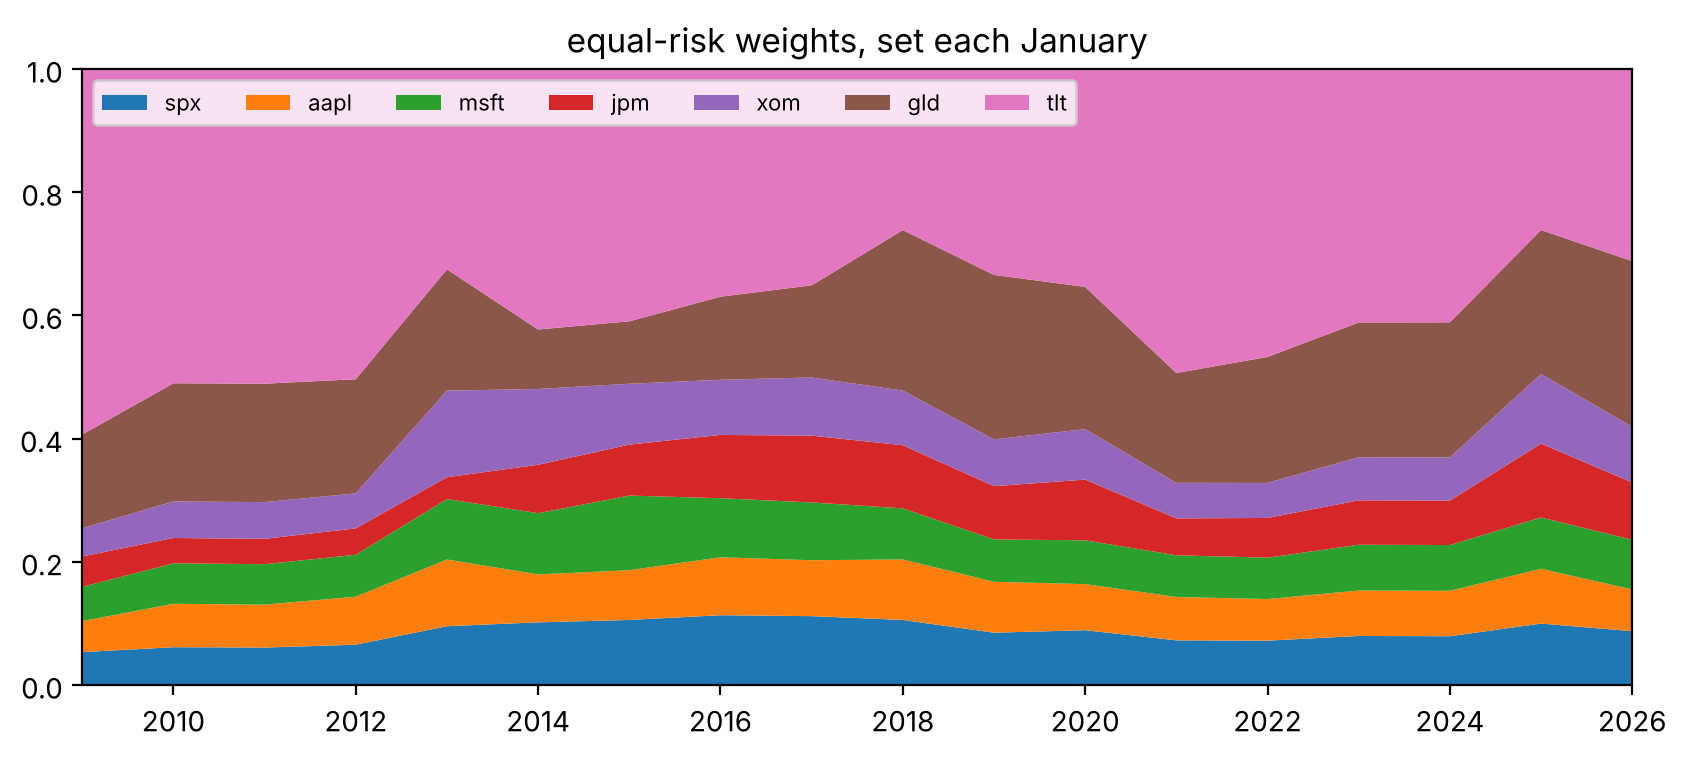

In [3]:
plt.figure(figsize=(10, 4))
plt.stackplot(yearly.index, yearly.T.values, labels=assets)
plt.xlim(yearly.index[0], yearly.index[-1]); plt.ylim(0, 1)
plt.legend(loc="upper left", ncol=7, fontsize=8); plt.title("equal-risk weights, set each January")
plt.show()
# bonds take 33-59% of the money most years, gold 10-27%, each stock 4-12%
# at the start of 2022 bonds are still 47%: the window is 2018-2021, when they went up on the bad days
# after 2022 the bond weight comes down slowly (41% in 2023-24, 26% in 2025): 4 years of memory

In [4]:
S = simple.loc[start:]
w_full = equal_risk_weights(simple.values)   # the look-ahead version of 07
ports = {"S&P 500": S.spx, "1/7": S @ np.full(7, 1 / 7),
         "equal risk, yearly": (S * W.loc[start:]).sum(axis=1), "equal risk, full period": S @ w_full}
wealth = {}
for nm, p in ports.items():
    lp = np.log1p(p)
    wealth[nm] = np.exp(lp.cumsum())
    dd = wealth[nm] / wealth[nm].cummax() - 1
    v, e = var_es_hist(lp.values)
    print(f"{nm:24s} return {252 * lp.mean():5.1%}  vol {np.sqrt(252) * lp.std():5.1%}  ES {e:.2%}  "
          f"max drawdown {dd.min():6.1%} ({dd.idxmin().date()})  2022 {np.expm1(lp.loc['2022'].sum()):6.1%}")
# out of sample the ES is 2.26% vs 2.09% with hindsight: knowing the future helped very little
# but 2022 hurts: -17.2%, almost like the S&P (-19.4%) and twice the 1/7 portfolio (-7.9%)
# its worst drawdown is 2022 (-22.6%), when for 1/7 and the S&P it is march 2020

S&P 500                  return 11.6%  vol 17.9%  ES 4.68%  max drawdown -33.9% (2020-03-23)  2022 -19.4%
1/7                      return 14.8%  vol 14.3%  ES 3.51%  max drawdown -25.9% (2020-03-23)  2022  -7.9%
equal risk, yearly       return  9.7%  vol  9.8%  ES 2.26%  max drawdown -22.6% (2022-10-20)  2022 -17.2%
equal risk, full period  return  9.6%  vol  9.5%  ES 2.09%  max drawdown -21.3% (2022-10-20)  2022 -16.1%


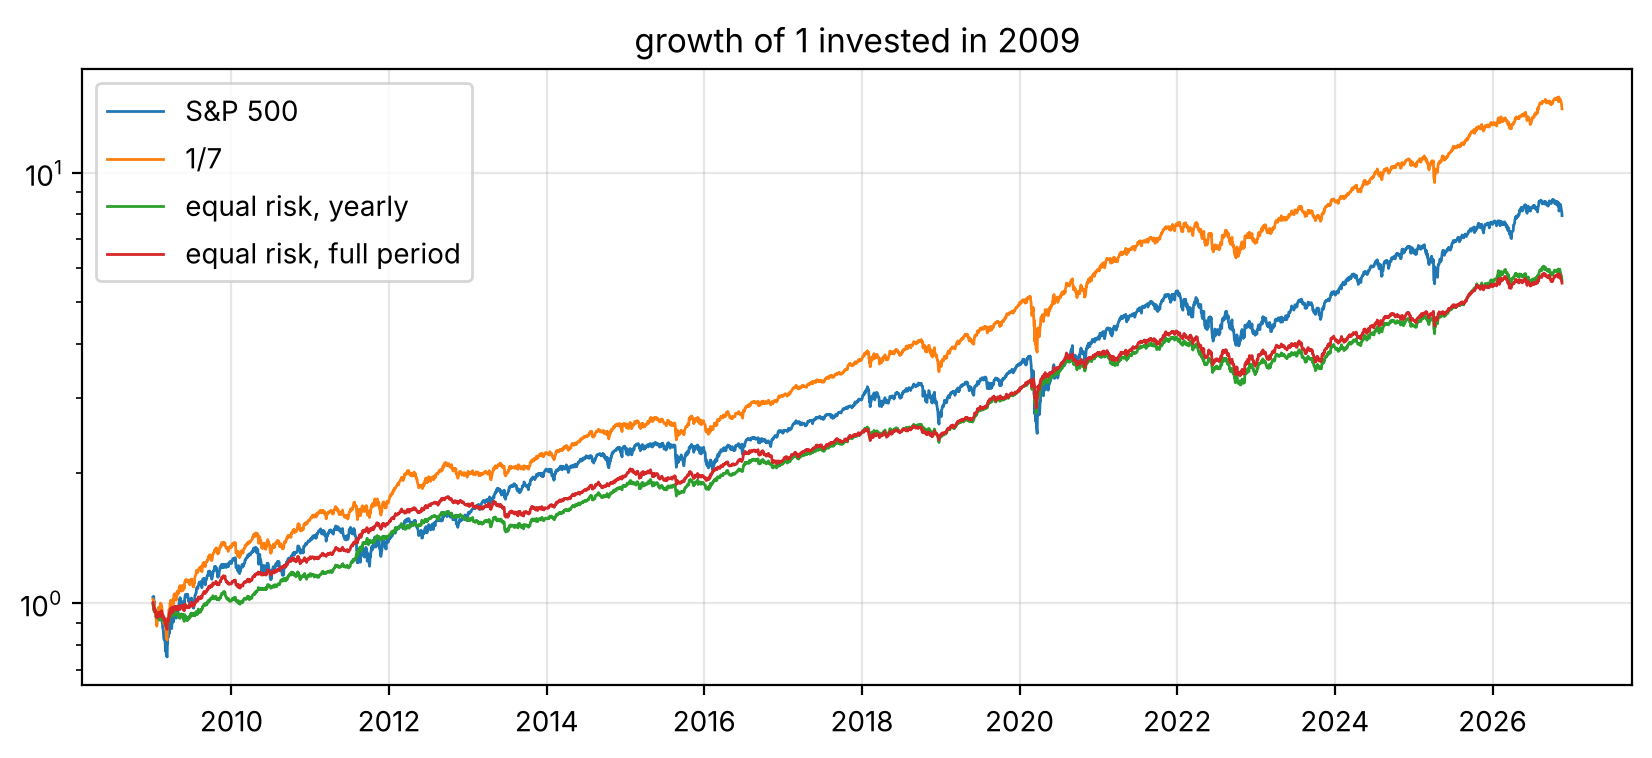

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for nm, w_ in wealth.items():
    ax.plot(w_, lw=1, label=nm)
ax.set_yscale("log"); ax.set_title("growth of 1 invested in 2009"); ax.grid(alpha=0.3); ax.legend()
plt.show()

In [6]:
print("share of the ES in 2022, with the weights set in january 2022:")
print(dict(zip(assets, es_contributions(S.loc["2022"].values, W.loc["2022"].iloc[0].values).round(2))))
# the bonds, meant to bring 1/7 of the risk, brought half of it in 2022
# the weights assume the dependence of the last 4 years carries on. it did for 13 years, then the stock-bond
# correlation turned positive (see 07) and the portfolio was built for the old regime
# a shorter window or a DCC correlation would react faster, at the cost of more turnover

share of the ES in 2022, with the weights set in january 2022:
{'spx': np.float64(0.08), 'aapl': np.float64(0.11), 'msft': np.float64(0.09), 'jpm': np.float64(0.04), 'xom': np.float64(0.07), 'gld': np.float64(0.12), 'tlt': np.float64(0.5)}
